# First Light — Market Behavior Atlas

**What this is.** A descriptive study of how the whole US equity universe in our database behaved from 2017 to 2026 under different market and macro conditions, and of which conditions came before exceptional stock performance. It is **not** a strategy backtest: nothing here is optimised, and no rule here is a trading signal.

**How to read the evidence.** Every result is tagged with one of three classes:

| Class | Meaning |
|---|---|
| **A — Descriptive** | True of *this dataset* (today's survivors, adjusted prices, 2017–2026). |
| **B — Plausibly general** | Consistent with how markets work and robust enough here that it probably holds for the historical market, but unconfirmed. |
| **C — Hypothesis** | Interesting, but needs an independent test on data not used here (ideally forward). |

**Ground rules.** Every regime label uses data up to the date it labels. Stock statistics are averaged month by month, so a month with 2,400 stocks does not outweigh a month with 1,500. Overlapping windows are never treated as independent: intervals use block bootstraps, and tables report the number of independent episodes. Correlation is not causation, and nothing here is presented as predictive alpha.

## 0. Setup and data

* **Prices:** `stock_prices` from the production database via the read-only, hashed extract `research/right_tail/extract.py`. Prices are vendor back-adjusted for splits, dividends and spin-offs.
* **Macro and market data (public):** FRED (latest vintage), ALFRED (CPI and payrolls *as first published*, with exact release dates) and federalreserve.gov (FOMC statement dates), fetched by `fetch_macro.py` into `data/macro/`.
* **Sector:** the sector observed in October 2026, applied to all history. This is **not** point-in-time.
* **Eligible stock on date t:** close ≥ \$5, 20-session average dollar volume ≥ \$2M, at least 252 earlier sessions, and no flagged price discontinuity in the last 252 sessions or in the forward window being measured.

In [1]:
import os, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.dates as mdates
import atlas_lib as A
warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.float_format", lambda x: f"{x:,.4g}")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3, "font.size": 9, "axes.titlesize": 10})
FIG = "figures"; os.makedirs(FIG, exist_ok=True)
def save(fig, name):
    fig.savefig(f"{FIG}/{name}.png", bbox_inches="tight", dpi=110); plt.show()
TREND_COL = {"Bull": "#2e7d32", "Recovery": "#9ccc65", "Weakening": "#ffa726", "Bear": "#c62828"}

p = A.load_panel("data/prices")
reg = A.build_regimes(p)
sec = pd.read_csv("data/sectors_observed_2026-10.csv").set_index("symbol")["sector"]
fp = A.attach(A.forward_panel(p), reg, sec)
print("extract:", {k: p.meta[k] for k in ("prices_rows", "prices_symbols", "prices_min_date", "prices_max_date", "prices_sha256")})
print("stray calendar dates dropped (fewer than 500 symbols priced):", p.meta["stray_dates_dropped"])
print("panel:", p.C.shape[0], "sessions x", p.C.shape[1], "symbols;", "month-end cross-sections:", fp["date"].nunique(), "; stock-month rows:", len(fp))
print("macro files:", sorted(os.listdir("data/macro")))

extract: {'prices_rows': 6519681, 'prices_symbols': 3114, 'prices_min_date': '2016-09-20', 'prices_max_date': '2026-10-30', 'prices_sha256': 'aefa1522c943654742c985825943cc2281393e3126a8ced21632f4762d9dcb74'}
stray calendar dates dropped (fewer than 500 symbols priced): {'2026-02-16': 1}
panel: 2543 sessions x 3114 symbols; month-end cross-sections: 110 ; stock-month rows: 210145
macro files: ['alfred_cache.json', 'fomc_press_releases.csv', 'fred_BAA10Y.csv', 'fred_BAMLH0A0HYM2.csv', 'fred_DFEDTARL.csv', 'fred_DFEDTARU.csv', 'fred_DFII10.csv', 'fred_DGS10.csv', 'fred_DGS2.csv', 'fred_DGS3MO.csv', 'fred_DTWEXBGS.csv', 'fred_NASDAQCOM.csv', 'fred_NFCI.csv', 'fred_SP500.csv', 'fred_T10Y2Y.csv', 'fred_VIXCLS.csv', 'fred_WALCL.csv', 'fred_meta.json', 'releases_cpi.csv', 'releases_jobs.csv']


## 1. Data integrity and survivorship — read this first

Every later number rests on this section. The key question is whether today's stock list can stand in for the historical investable universe. It cannot.

In [2]:
C = p.C
first = C.apply(lambda s: s.first_valid_index()); last = C.apply(lambda s: s.last_valid_index())
data_end = C.index[-1]
yr = pd.DataFrame({
    "symbols with any price": C.notna().groupby(C.index.year).any().sum(axis=1),
    "first appearance (new listings)": first.dt.year.value_counts().reindex(sorted(set(C.index.year)), fill_value=0),
    "series ending before 2026-09": last[last < pd.Timestamp("2026-09-01")].dt.year.value_counts().reindex(sorted(set(C.index.year)), fill_value=0),
})
yr.loc[yr.index.min(), "first appearance (new listings)"] = np.nan          # the extract starts in 2016: "first appearance" that year is the data start, not a listing
print(yr.to_string())
me = A.month_ends(C.index, "2017-09-01")
elig_me = p.eligible.loc[me].sum(axis=1)
in_fp = fp.groupby("date").size().reindex(me, fill_value=0)
r250_missing = fp.assign(m=fp["r250"].isna()).groupby("date")["m"].mean()
start_set = set(fp.loc[fp["date"] == me[0], "symbol"])
still = sum(1 for s in start_set if last[s] >= pd.Timestamp("2026-09-01"))
print(f"\nStocks eligible on {me[0].date()}: {len(start_set)}; still priced in Sep 2026: {still} ({still / len(start_set):.1%}).")
print(f"Eligible stock-months removed by the discontinuity lookback rule: {1 - in_fp.sum() / elig_me.sum():.2%}")
print(f"Flagged discontinuities: {int(p.disc.values.sum())} symbol-days on {int(p.disc.any().sum())} symbols")
mature = fp[fp["date"] <= C.index[-251]]
print(f"Mature 250-session windows with NO closing price at t+250 (stock vanished or a discontinuity): {mature['r250'].isna().mean():.2%} of {len(mature):,}")

      symbols with any price  first appearance (new listings)  series ending before 2026-09
2016                    2050                              NaN                             0
2017                    2144                               94                             0
2018                    2242                              100                             0
2019                    2341                               98                             0
2020                    2482                              141                             0
2021                    2700                              219                             0
2022                    2755                               55                             0
2023                    2811                               57                             0
2024                    2888                               77                             0
2025                    2994                              105                   

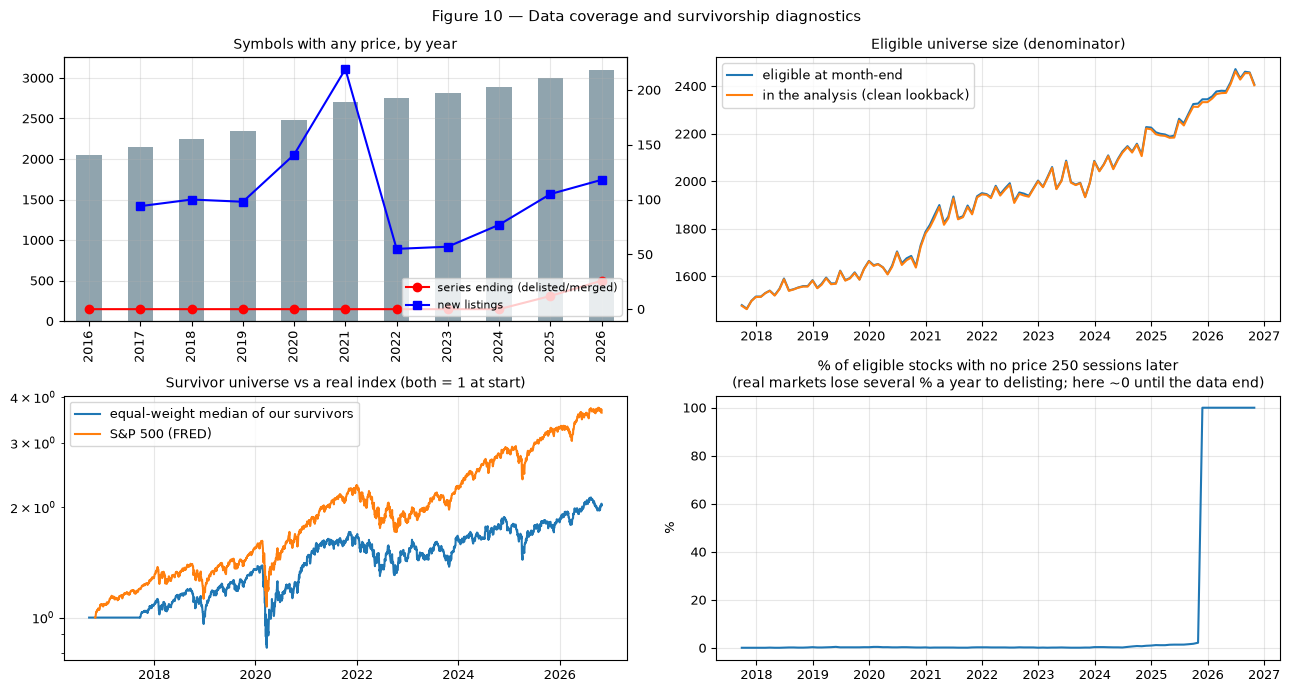

In [3]:
fig, ax = plt.subplots(2, 2, figsize=(13, 7))
yr[["symbols with any price"]].plot.bar(ax=ax[0, 0], color="#90a4ae", legend=False); ax[0, 0].set_title("Symbols with any price, by year")
a2 = ax[0, 0].twinx(); a2.plot(range(len(yr)), yr["series ending before 2026-09"], "r-o", label="series ending (delisted/merged)"); a2.plot(range(len(yr)), yr["first appearance (new listings)"], "b-s", label="new listings"); a2.legend(loc="lower right", fontsize=8); a2.grid(False)
ax[0, 1].plot(elig_me.index, elig_me.values, label="eligible at month-end"); ax[0, 1].plot(in_fp.index, in_fp.values, label="in the analysis (clean lookback)"); ax[0, 1].legend(); ax[0, 1].set_title("Eligible universe size (denominator)")
ewn = reg["ew_index"] / reg["ew_index"].loc[reg["spx"].first_valid_index()]; spn = reg["spx"] / reg["spx"].dropna().iloc[0]
ax[1, 0].plot(ewn.index, ewn, label="equal-weight median of our survivors"); ax[1, 0].plot(spn.index, spn, label="S&P 500 (FRED)"); ax[1, 0].set_yscale("log"); ax[1, 0].legend(); ax[1, 0].set_title("Survivor universe vs a real index (both = 1 at start)")
ax[1, 1].plot(r250_missing.index, r250_missing.values * 100); ax[1, 1].set_title("% of eligible stocks with no price 250 sessions later\n(real markets lose several % a year to delisting; here ~0 until the data end)"); ax[1, 1].set_ylabel("%")
fig.suptitle("Figure 10 — Data coverage and survivorship diagnostics", fontsize=11); fig.tight_layout(); save(fig, "fig10_coverage_survivorship")

### What §1 shows

* **[A] Survivorship is close to total.** Of the 1,476 stocks eligible on 2017-09-29, **98.3%** still had a price in September 2026. Across all mature windows, only **0.39%** of eligible stocks lost their price within 250 sessions. Only 38 of 3,114 series end before September 2026, all in 2025–26. Real markets lose several percent of listed companies every year to delisting, bankruptcy and acquisition; this dataset has almost none of them.
* **Consequences, which apply to every later section:**
  * Loss-tail frequencies (≤ −50%, ≤ −75%) are **understated**, because bankruptcies are missing.
  * Winner frequencies and median returns are **overstated**, because the denominator excludes the companies that died.
  * The equal-weight "universe" line rises faster than the S&P 500 partly *because* it only contains survivors.
  * Any comparison *between* groups is affected only if the missing companies are unevenly spread across those groups. Weak-breadth and high-volatility periods are exactly where more companies would have failed, so their apparent advantage below is probably **overstated**.
* **[A] Two data-quality problems were found and fixed.** One vendor row priced a single symbol (CBL) on a market holiday (2026-02-16). Left in, it broke every 200-day average for 200 sessions; the load step now drops such dates and records them. Separately, flagged price discontinuities remove 0.25% of eligible stock-months.

## 2. Market regimes (point-in-time, transparent)

| Dimension | Definition (computed only from data up to that day) | Source |
|---|---|---|
| **Trend** | Bull: S&P 500 above its 200-day average and the average rising over 20 sessions. Recovery: above a still-falling average. Weakening: below a still-rising average. Bear: below a falling average. | FRED SP500 |
| **Momentum** | S&P 500 126-session return > +10% "Strong up", < −10% "Down", else "Sideways". | FRED SP500 |
| **Volatility** | VIX < 15 low, 15–25 mid, > 25 high. | FRED VIXCLS |
| **Breadth** | Share of eligible stocks above their own 200-day average: < 40% weak, 40–60% mid, > 60% strong (survivor universe; see §1). | our prices |
| **Financial conditions** | Baa corporate–Treasury spread above its own trailing one-year median = tighter, below = looser. NFCI is shown as a cross-check, but it is *revised*. | FRED BAA10Y, NFCI |

None of these is fitted to future returns. Robustness: the trend labels are recomputed with a 150-day average and 10-day slope, and with a 250-day average and 40-day slope.

In [4]:
dims = ["trend", "momentum", "volatility", "breadth_regime", "fin_conditions"]
tab = []
for d in dims:
    lab = reg[d].dropna()
    for v, n in lab.value_counts().items():
        tab.append({"dimension": d, "regime": v, "sessions": n, "share": n / len(lab), "separate spells": A.spells(lab, v)})
print(pd.DataFrame(tab).to_string(index=False))
print("\nRobustness of the trend definition (share of days with the same label):"); print(A.regime_agreement(p).to_string(index=False))
print("\nMonth-end trend label sequence (B=Bull R=Recovery W=Weakening X=Bear):")
mt = reg["trend"].reindex(me).dropna().map({"Bull": "B", "Recovery": "R", "Weakening": "W", "Bear": "X"})
for y in sorted(set(mt.index.year)): print(y, "".join(mt[mt.index.year == y]))

     dimension                           regime  sessions   share  separate spells
         trend                             Bull      1782  0.7708               24
         trend                             Bear       296   0.128               10
         trend                        Weakening       138 0.05969               23
         trend                         Recovery        96 0.04152               11
      momentum                         Sideways      1398  0.5862               76
      momentum                        Strong up       881  0.3694               62
      momentum                             Down       106 0.04444               14
    volatility                  Mid vol (15-25)      1328  0.5222              114
    volatility                    Low vol (<15)       852   0.335               65
    volatility                   High vol (>25)       363  0.1427               48
breadth_regime            Strong breadth (>60%)      1274  0.5561               64
brea

                   alternative  days_compared  same_label_share
SMA150, slope over 10 sessions           2312             0.869
SMA250, slope over 40 sessions           2262              0.87

Month-end trend label sequence (B=Bull R=Recovery W=Weakening X=Bear):
2017 BBBB
2018 BBBBBBBBBWXX
2019 XBBBWBBBBBBB
2020 BWXXRBBBBBBB
2021 BBBBBBBBBBBB
2022 BWBWXXXXXXRX
2023 RRRBBBBBBWBB
2024 BBBBBBBBBBBB
2025 BBWXBBBBBBBB
2026 BBWBBBBBBB


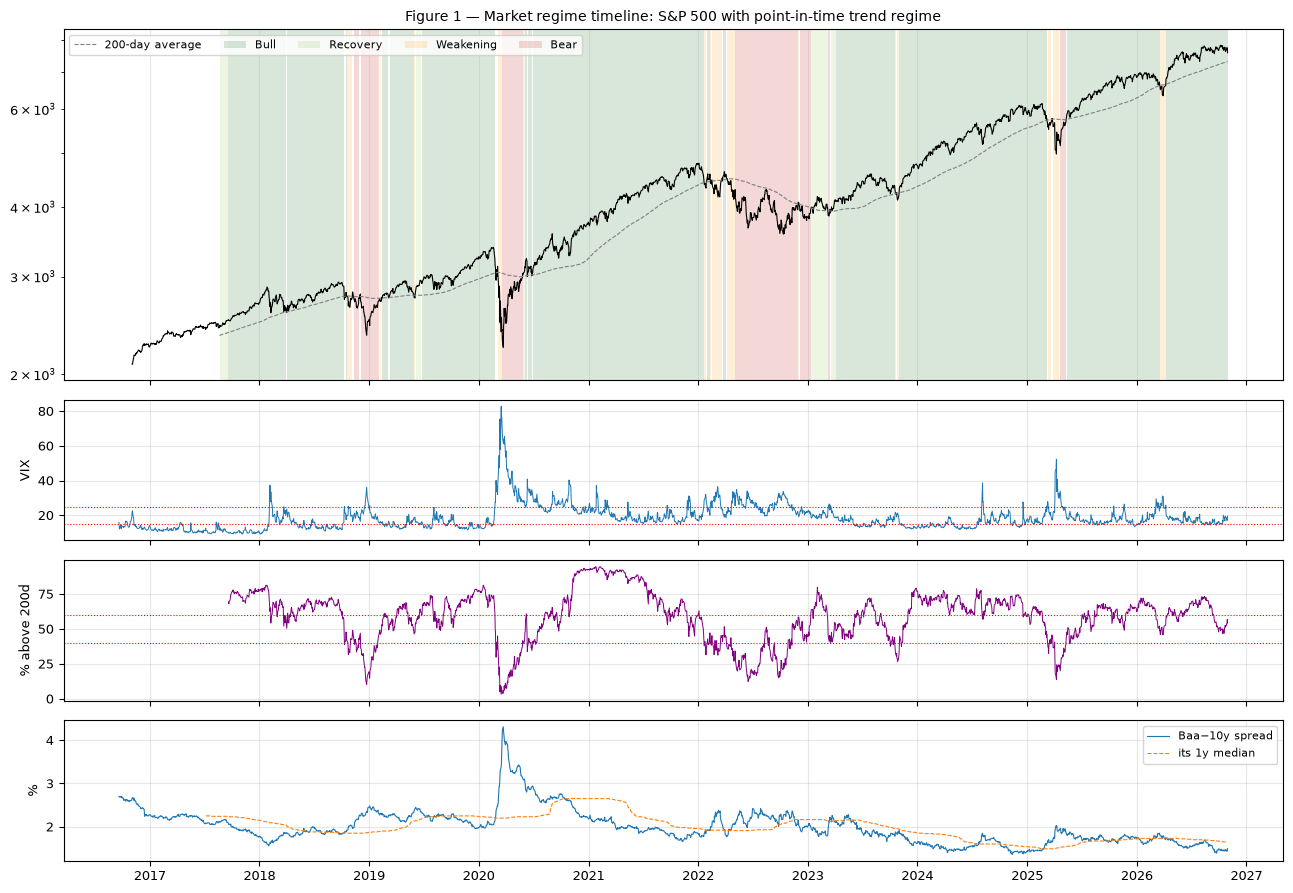

In [5]:
fig, ax = plt.subplots(4, 1, figsize=(13, 9), sharex=True, gridspec_kw={"height_ratios": [3, 1.2, 1.2, 1.2]})
s = reg["spx"].dropna()
ax[0].plot(s.index, s.values, "k-", lw=.8); ax[0].plot(reg["spx_sma"].index, reg["spx_sma"], color="gray", lw=.8, ls="--", label="200-day average"); ax[0].set_yscale("log")
lab = reg["trend"]
for k, col in TREND_COL.items():
    m = (lab == k).astype(int); ax[0].fill_between(lab.index, 0, 1, where=m.values == 1, transform=ax[0].get_xaxis_transform(), color=col, alpha=.18, lw=0, label=k)
ax[0].legend(ncol=5, fontsize=8, loc="upper left"); ax[0].set_title("Figure 1 — Market regime timeline: S&P 500 with point-in-time trend regime")
ax[1].plot(reg["vix"].index, reg["vix"], lw=.7); [ax[1].axhline(x, color="r", ls=":", lw=.8) for x in (15, 25)]; ax[1].set_ylabel("VIX")
ax[2].plot(reg["breadth"].index, reg["breadth"] * 100, lw=.7, color="purple"); [ax[2].axhline(x, color="r", ls=":", lw=.8) for x in (40, 60)]; ax[2].set_ylabel("% above 200d")
ax[3].plot(reg["baa10y"].index, reg["baa10y"], lw=.8, label="Baa−10y spread"); ax[3].plot(reg.index, reg["baa10y"].rolling(252, min_periods=200).median(), ls="--", lw=.8, label="its 1y median"); ax[3].set_ylabel("%"); ax[3].legend(fontsize=8)
ax[3].xaxis.set_major_locator(mdates.YearLocator()); fig.tight_layout(); save(fig, "fig01_regime_timeline")

### What §2 shows

* **[A] The sample holds few independent market episodes.**
  * Bear months (month-end labels) come in 5 separate spells: November 2018–January 2019, March–April 2020, May–October 2022, December 2022 and April 2025.
  * Recovery has 3 spells and Weakening 7.
  * 77% of all sessions are labelled Bull.

  Every regime comparison below rests on a handful of episodes. The **spells** column, not the number of stock-months, is the honest sample size.
* **[A] The trend labels are reasonably stable.** The two alternative definitions agree on 87% of days; most disagreements are at turning points.
* The volatility and breadth regimes switch far more often (37–114 spells) than the trend regime, so they describe short-lived states rather than market eras.

## 3. Macro events: FOMC, CPI, employment

**Important — no consensus forecasts.** We have no historical market expectations (no survey consensus, no fed funds futures), so **this is a descriptive event study, not a surprise study**. Where events are split into groups, the split uses:
* For CPI and payrolls: the **first-release** number against a naive benchmark (the previous month as published in the same release). This is *not* what markets expected.
* For FOMC: the actual decision (hike/cut/hold, from the target range), and as a market-implied proxy the direction of the 2-year Treasury yield on the day. That proxy is **contemporaneous**, so it describes the reaction and cannot predict it.

Returns run from the close before the event to the close k sessions after it (k = 0 is the event day itself; CPI and jobs are released at 8:30 ET, FOMC at 14:00 ET). Each group is compared with the *unconditional* average of the same window over all days, because a 120-session window is mostly ordinary market drift. Events are about a month apart, but 60- and 120-session windows overlap heavily, so their intervals are too narrow and are shown for orientation only.

In [6]:
HAVE = {k: os.path.exists(f"data/macro/releases_{k}.csv") for k in ("cpi", "jobs")}
fomc = A.fomc_decisions()
cpi = A.releases_from_cache("cpi") if HAVE["cpi"] else None
jobs = A.releases_from_cache("jobs") if HAVE["jobs"] else None
for k, v in HAVE.items():
    if not v: print(f"*** {k.upper()} release table not collected yet (ALFRED crawl still running): that part of the event study is PENDING, not empty. ***")
spx, ewi = reg["spx"].dropna(), reg["ew_index"]
cov = spx.index[0]
dgs2 = A.fred("DGS2")
fomc["dy2_bp"] = [ (dgs2.loc[:d].iloc[-1] - dgs2.loc[:d - pd.Timedelta(days=1)].iloc[-1]) * 100 if len(dgs2.loc[:d - pd.Timedelta(days=1)]) else np.nan for d in fomc["date"]]
print("FOMC statements:", len(fomc), fomc["decision"].value_counts().to_dict(), "| CPI releases:", None if cpi is None else len(cpi), "| jobs reports:", None if jobs is None else len(jobs))
for nm, t in (("CPI", cpi), ("Jobs", jobs)):
    if t is not None:
        lag = (t["release_date"] - t["ref_month"]).dt.days
        print(f"{nm}: {t['release_date'].min().date()} -> {t['release_date'].max().date()}; days from reference month start to release: median {lag.median():.0f}, max {lag.max():.0f} "
              f"(late releases: {list(t.loc[lag > 50, 'release_date'].dt.date.astype(str))})")
KS = (0, 5, 20, 60, 120)
unc = {nm: A.unconditional(s, KS) for nm, s in (("S&P 500", spx), ("Universe median", ewi.loc[cov:]))}
allday_abs = {nm: float((s / s.shift(1) - 1).abs().mean()) for nm, s in (("S&P 500", spx), ("Universe median", ewi.loc[cov:]))}

def evt_table(groups):
    rows = []
    for nm, s in (("S&P 500", spx), ("Universe median", ewi.loc[cov:])):
        for g, dates in groups.items():
            er = A.event_returns(s, pd.DatetimeIndex(dates)[pd.DatetimeIndex(dates) >= cov], KS)
            if len(er) == 0: continue
            r = {"series": nm, "group": g, "events": len(er), "abs move day0 vs all days": er["k0"].abs().mean() / allday_abs[nm]}
            for k in KS:
                dm, lo, hi = A.diff_ci(er[f"k{k}"].values, unc[nm][k])
                r[f"k{k} mean"] = er[f"k{k}"].mean(); r[f"k{k} minus all-days"] = dm
                if k in (0, 20): r[f"k{k} diff 95% CI"] = f"[{lo:+.4f}, {hi:+.4f}]"
            rows.append(r)
    return pd.DataFrame(rows)

G = {}
G["FOMC"] = {"all statements": fomc["date"], **{k: v["date"] for k, v in fomc.groupby("decision")}, "2y yield rose on the day (hawkish read)": fomc.loc[fomc["dy2_bp"] > 0, "date"], "2y yield fell on the day (dovish read)": fomc.loc[fomc["dy2_bp"] < 0, "date"]}
if cpi is not None:
    cpi["hot"] = np.where(cpi["headline_mom"] - cpi["headline_mom_prev"] > 0.05, "hotter than prior month", np.where(cpi["headline_mom"] - cpi["headline_mom_prev"] < -0.05, "cooler than prior month", "about the same"))
    G["CPI"] = {"all CPI releases": cpi["release_date"], **{k: v["release_date"] for k, v in cpi.groupby("hot")}}
if jobs is not None:
    jobs["pay_vs3"] = np.where(jobs["payrolls_change_k"] > jobs["payrolls_prev3_mean_k"], "payrolls above prior 3-mo avg", "payrolls below prior 3-mo avg")
    jobs["u"] = np.where(jobs["unrate_change"] > 0.05, "unemployment up", np.where(jobs["unrate_change"] < -0.05, "unemployment down", "unemployment unchanged"))
    G["Jobs"] = {"all jobs reports": jobs["release_date"], **{k: v["release_date"] for k, v in jobs.groupby("pay_vs3")}, **{k: v["release_date"] for k, v in jobs.groupby("u")}}
ET = {k: evt_table(v) for k, v in G.items()}
cols = ["series", "group", "events", "abs move day0 vs all days", "k0 mean", "k0 diff 95% CI", "k5 minus all-days", "k20 minus all-days", "k20 diff 95% CI", "k60 minus all-days", "k120 minus all-days"]
for k, t in ET.items():
    print(f"\n=== {k} ===  (all-days means S&P 500: " + ", ".join(f"k{x}={unc['S&P 500'][x]:+.4f}" for x in KS) + ")"); print(t[cols].to_string(index=False))

FOMC statements: 89 {'Hold': 58, 'Hike': 20, 'Cut': 11} | CPI releases: 128 | jobs reports: 129
CPI: 2016-02-19 -> 2026-10-14; days from reference month start to release: median 42, max 53 (late releases: ['2025-10-24'])
Jobs: 2016-02-05 -> 2026-10-02; days from reference month start to release: median 34, max 80 (late releases: ['2025-11-20', '2025-12-16'])



=== FOMC ===  (all-days means S&P 500: k0=+0.0006, k5=+0.0034, k20=+0.0118, k60=+0.0337, k120=+0.0665)
         series                                   group  events  abs move day0 vs all days    k0 mean     k0 diff 95% CI  k5 minus all-days  k20 minus all-days    k20 diff 95% CI  k60 minus all-days  k120 minus all-days
        S&P 500                          all statements      82                      1.327  -0.001823 [-0.0065, +0.0011]          -0.003929            0.001804 [-0.0083, +0.0118]            0.004332             0.005507
        S&P 500                                     Cut      11                      2.592   -0.01586 [-0.0402, -0.0007]           -0.02961            -0.01562 [-0.0572, +0.0114]           0.0004211             -0.03046
        S&P 500                                    Hike      20                      1.508  7.107e-05 [-0.0069, +0.0058]          -0.007583           -0.003702 [-0.0198, +0.0117]            -0.01979             -0.02537
        S&P 500 

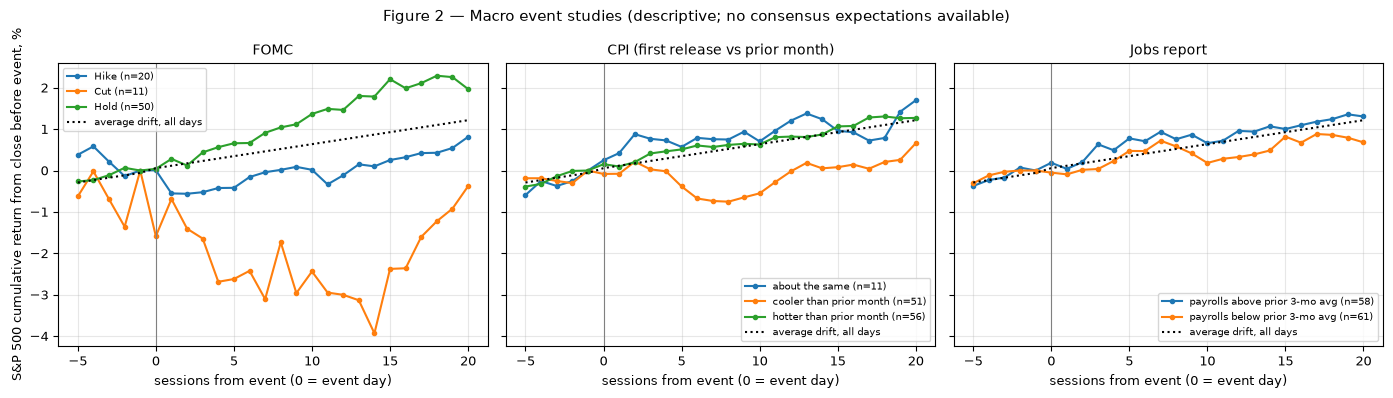

In [7]:
def path(s, dates, lo=-5, hi=20):
    s = s.dropna(); ix = s.index; out = []
    for e in pd.DatetimeIndex(dates):
        i = ix.searchsorted(e)
        if i + lo - 1 < 0 or i + hi >= len(ix): continue
        base = s.iloc[i - 1]; out.append([s.iloc[i + k] / base - 1 for k in range(lo, hi + 1)])
    return np.array(out)
fig, ax = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
xs = np.arange(-5, 21)
drift = np.array([unc["S&P 500"][0] * 0] + [0] * 0)
dd = (spx / spx.shift(1) - 1).mean()
for a, (title, groups) in zip(ax, [("FOMC", {"Hike": G["FOMC"]["Hike"], "Cut": G["FOMC"]["Cut"], "Hold": G["FOMC"]["Hold"]}),
                                   ("CPI (first release vs prior month)", {k: v for k, v in G.get("CPI", {}).items() if k != "all CPI releases"}),
                                   ("Jobs report", {k: v for k, v in G.get("Jobs", {}).items() if k.startswith("payrolls")})]):
    if not groups:
        a.text(.5, .5, f"{title}:\nrelease table pending\n(ALFRED collection running)", ha="center", va="center", transform=a.transAxes); a.set_title(title); continue
    for g, dts in groups.items():
        P = path(spx, dts)
        if len(P): a.plot(xs, P.mean(0) * 100, marker=".", label=f"{g} (n={len(P)})")
    a.plot(xs, np.where(xs >= 0, (xs + 1) * dd, xs * dd) * 100, "k:", label="average drift, all days")
    a.axvline(0, color="gray", lw=.8); a.set_title(title); a.set_xlabel("sessions from event (0 = event day)"); a.legend(fontsize=7)
ax[0].set_ylabel("S&P 500 cumulative return from close before event, %")
fig.suptitle("Figure 2 — Macro event studies (descriptive; no consensus expectations available)"); fig.tight_layout(); save(fig, "fig02_macro_event_study")

### 3b. Rates, credit and liquidity *states* (not events) and what followed

These are monthly observations, each describing the state at month-end with data available then. Long-horizon windows overlap, so the *spells* column is the honest count of independent episodes.

In [8]:
dgs10, dfii, walcl = A.fred("DGS10"), A.fred("DFII10"), A.fred("WALCL")
M = pd.DataFrame(index=me)
M["d10y_60"] = (dgs10.reindex(C.index).ffill() - dgs10.reindex(C.index).ffill().shift(60)).reindex(me)
M["real10_60"] = (dfii.reindex(C.index).ffill() - dfii.reindex(C.index).ffill().shift(60)).reindex(me)
M["walcl_13w"] = (walcl.reindex(C.index).ffill() / walcl.reindex(C.index).ffill().shift(63) - 1).reindex(me)
M["fin"] = reg["fin_conditions"].reindex(me)
for h in (60, 120):
    M[f"spx_f{h}"] = (spx.reindex(C.index).ffill().shift(-h) / spx.reindex(C.index).ffill() - 1).reindex(me)
    M[f"univ_med_f{h}"] = fp.groupby("date")[f"r{h}"].median().reindex(me)
M["rates"] = np.where(M["d10y_60"] > 0.5, "10y yield up >50bp in 60d", np.where(M["d10y_60"] < -0.5, "10y yield down >50bp in 60d", "10y yield roughly stable"))
M["real"] = np.where(M["real10_60"] > 0.4, "real yield up >40bp", np.where(M["real10_60"] < -0.4, "real yield down >40bp", "real yield stable"))
M["liq"] = np.where(M["walcl_13w"] > 0.02, "Fed balance sheet growing >2%/13w", np.where(M["walcl_13w"] < -0.02, "Fed balance sheet shrinking >2%/13w", "Fed balance sheet ~flat"))
M.loc[M["d10y_60"].isna(), "rates"] = np.nan
rows = []
for dim in ("rates", "real", "liq", "fin"):
    for g, sub in M.dropna(subset=[dim]).groupby(dim):
        rows.append({"state": g, "months": len(sub), "spells": A.spells(M[dim].dropna(), g), "S&P next 60d mean": sub["spx_f60"].mean(), "S&P next 120d mean": sub["spx_f120"].mean(),
                     "universe median stock next 60d": sub["univ_med_f60"].mean(), "universe median next 120d": sub["univ_med_f120"].mean()})
print(pd.DataFrame(rows).to_string(index=False))

                              state  months  spells  S&P next 60d mean  S&P next 120d mean  universe median stock next 60d  universe median next 120d
        10y yield down >50bp in 60d      10       6            0.06989              0.1414                         0.04158                    0.08974
           10y yield roughly stable      86      15            0.02762             0.05238                         0.01687                    0.02947
          10y yield up >50bp in 60d      14       8            0.02688             0.06069                         0.02565                    0.02791
              real yield down >40bp       7       5            0.04913              0.1216                         0.04341                     0.1211
                  real yield stable      88      15            0.03095             0.05626                         0.01817                    0.02788
                real yield up >40bp      15       9            0.02593             0.06687          

### What §3 shows (descriptive; there are no consensus forecasts)

* **[A] FOMC days are about 1.3× as volatile as an ordinary day** (S&P 500 absolute move, 82 statements since November 2016).
  * The 11 **cut** days averaged −1.6% (95% interval −4.0% to −0.1%) and were 2.6× as volatile as a normal day.
  * These are mostly emergency or early-cycle cuts (March 2020, 2019, late 2024–25). This is a selection effect, not a reaction to cuts as such: the Fed cuts when something is going wrong.
  * The "hawkish read" split (the 2-year yield rose that day) has a negative day-0 return *by construction*: it describes the reaction, it does not predict it.
  * After hold meetings, the 20- to 120-session drift is not distinguishable from an ordinary day.
* **[A] CPI days were only about 1.08× as volatile as an ordinary day across 2016–2026** (119 releases inside the S&P 500 window). Splitting releases by the first-release month-on-month change against the previous month (hotter 57, cooler 51, about the same 11) produces **no group whose 20-session difference from ordinary drift excludes zero**.
  * That split is a naive benchmark, not a surprise: without consensus forecasts we cannot say what was *unexpected*.
* **[A] Jobs-report days were about 1.18× as volatile as an ordinary day** (120 reports in the S&P 500 window; release dates and first-release values from ALFRED, including the shutdown-delayed 2025-11-20 and 2025-12-16 reports).
  * Days when first-release unemployment *rose* were the most volatile (1.42×).
  * Splitting by payrolls above vs below their prior three-month average, or by unemployment up, flat or down, gives **no group whose day-0 or 20-session difference from ordinary drift excludes zero**.
  * Payrolls above trend were followed by slightly better 120-session S&P 500 returns (+2.2% vs −2.0% relative to ordinary drift). These windows overlap heavily and are not evidence.
* **[C] Rates, credit and liquidity states.**
  * Months after the 10-year yield had fallen more than 50 bp in 60 sessions were followed by stronger S&P 500 returns: +7.0% over the next 60 sessions vs +2.8% when yields were stable. That is only 6 separate spells, and they include the 2020 and 2023–24 rate collapses.
  * Months with **tighter** credit (Baa spread above its one-year median) were followed by *better* returns than looser months (S&P 500 +3.8% vs +2.7% over 60 sessions).
  * Fed balance-sheet expansion vs contraction shows no consistent pattern (only 2–3 spells each).

  None of these comes close to being evidence; they are prompts for longer-history data.

## 4. Whole-universe forward performance

At each month-end, every eligible stock gets an outcome: its close-to-close return over the next 20, 60, 120 and 250 sessions, and the worst drawdown inside the next 250 sessions. Statistics are computed **within each month first and then averaged across months**, so each month counts once and one stock appearing in many months is not treated as many independent stocks. The tables give the number of months, the number of separate regime spells, stock-month observations and unique stocks.

In [9]:
rows = []
for h in A.HORIZONS:
    col = f"r{h}"; d = fp.dropna(subset=[col]); g = d.groupby("date")[col]
    rows.append({"horizon": h, "months": d["date"].nunique(), "stock-months": len(d), "unique stocks": d["symbol"].nunique(), "avg stocks/month": round(len(d) / d["date"].nunique()),
                 "median": g.median().mean(), "mean": g.mean().mean(), "IQR": (g.quantile(.75) - g.quantile(.25)).mean(), "skew": g.skew().mean(),
                 **{f">=+{int(x*100)}%": g.apply(lambda s, x=x: (s >= x).mean()).mean() for x in A.GAINS}, **{f"<=-{int(x*100)}%": g.apply(lambda s, x=x: (s <= -x).mean()).mean() for x in A.LOSSES},
                 "median stock vs universe-median path": d.groupby("date")[f"x{h}"].median().mean(), "mean stock vs its sector median": d.groupby("date")[f"xs{h}"].mean().mean()})
print("Unconditional forward outcomes of an eligible stock (month-equal weighted):"); print(pd.DataFrame(rows).set_index("horizon").T.to_string())
d = fp.dropna(subset=["r250"])
print(f"\nMax drawdown inside the next 250 sessions: median {d.groupby('date')['maxdd250'].median().mean():.1%}; share with a drawdown worse than -50%: {d.groupby('date')['maxdd250'].apply(lambda s: (s <= -.5).mean()).mean():.1%}")
print(f"Max gain reached inside 250 sessions (MFE) vs held to 250: >=+100% reached {d.groupby('date')['maxgain250'].apply(lambda s: (s >= 1).mean()).mean():.1%} vs held {d.groupby('date')['r250'].apply(lambda s: (s >= 1).mean()).mean():.1%}")
def sector_r2(df, col):
    out = []
    for t, x in df.dropna(subset=[col]).groupby("date"):
        x = x[x["sector"] != "Unknown"]
        if len(x) < 100: continue
        tot = x[col].var(); between = x.groupby("sector")[col].transform("mean").var()
        out.append(between / tot)
    return float(np.mean(out))
print("Share of cross-sectional return variance explained by sector (today's sector labels):", {h: round(sector_r2(fp, f'r{h}'), 3) for h in (20, 60, 250)})

Unconditional forward outcomes of an eligible stock (month-equal weighted):
horizon                                    20        60        120       250
months                                     109       107       104        98
stock-months                         2.076e+05 2.026e+05 1.951e+05 1.807e+05
unique stocks                            2,841     2,807     2,763     2,701
avg stocks/month                         1,905     1,893     1,876     1,844
median                                0.007105   0.02025   0.03507   0.07736
mean                                   0.01132    0.0321   0.06008    0.1327
IQR                                     0.1057    0.1962    0.2815    0.4275
skew                                     1.434     2.052     2.233     3.219
>=+25%                                 0.03286    0.1094    0.1862    0.2972
>=+50%                                0.005029   0.02653   0.06481    0.1447
>=+100%                              0.0006091  0.004494   0.01519   0.04514


Share of cross-sectional return variance explained by sector (today's sector labels): {20: 0.076, 60: 0.076, 250: 0.084}


In [10]:
BR = {dim: A.by_regime(fp, dim, 250) for dim in ["trend", "momentum", "volatility", "breadth_regime", "fin_conditions"]}
for dim, t in BR.items():
    print(f"\n=== 250-session outcomes by {dim} at the start month ==="); print(t.T.to_string())
print("\n=== 60-session outcomes by trend ==="); print(A.by_regime(fp, "trend", 60).drop(columns=["median_maxdd250"]).T.to_string())


=== 250-session outcomes by trend at the start month ===
trend                        Bear              Bull    Recovery   Weakening
months                         13                73           5           7
spells                          5                 8           3           7
stock_obs                   23723            134622        9635       12718
unique_stocks                2437              2678        2146        2386
mean_stocks_per_month       1,825             1,844       1,927       1,817
median_return              0.1815            0.0519      0.1491       0.098
mean_return                 0.251            0.1034      0.2219      0.1548
dispersion_iqr             0.4492            0.4212       0.456      0.4323
skew                         3.17              3.26         3.4        2.74
gain>=25%                  0.3918            0.2731      0.3733      0.3177
gain>=50%                  0.2061             0.129      0.2047       0.151
gain>=100%                 0.0

trend                              Bear              Bull    Recovery         Weakening
months                               13                81           5                 8
spells                                5                 9           3                 8
stock_obs                         23777            154032        9648             15126
unique_stocks                      2448              2792        2151              2579
mean_stocks_per_month             1,829             1,902       1,930             1,891
median_return                     0.059            0.0153     -0.0052            0.0233
mean_return                      0.0745            0.0259      0.0085            0.0412
dispersion_iqr                   0.2007            0.1948      0.1849            0.2099
skew                               1.91              2.01         1.5              3.08
gain>=25%                         0.146            0.1032      0.0833            0.1295
gain>=50%                       

**Robustness: is the regime pattern just 2020?** The 2020 crash and rebound is one episode, but it supplies many stock-months. Below: the ≥100% share by start year, and the regime tables recomputed **without any start month in 2020**.

In [11]:
d250 = fp.dropna(subset=["r250"])
yr_rate = d250.groupby(d250["date"].dt.year).apply(lambda s: pd.Series({"months": s["date"].nunique(), "share >=+100%": s.groupby("date")["r250"].apply(lambda x: (x >= 1).mean()).mean(),
                                                                         "share <=-50%": s.groupby("date")["r250"].apply(lambda x: (x <= -.5).mean()).mean(), "median 250d": s.groupby("date")["r250"].median().mean()}))
print("By start year:"); print(yr_rate.to_string())
ex = fp[fp["date"].dt.year != 2020]
for dim in ("trend", "volatility", "breadth_regime", "fin_conditions"):
    t = A.by_regime(ex, dim, 250)[["months", "spells", "median_return", "gain>=50%", "gain>=100%", "gain>=200%", "loss>=50%"]]
    print(f"\n{dim}, 2020 start months EXCLUDED:"); print(t.to_string())

By start year:
      months  share >=+100%  share <=-50%  median 250d
date                                                  
2017       4        0.01624       0.02982    0.0008822
2018      12        0.01254       0.03176      0.05478
2019      12        0.02489       0.06897     -0.03324
2020      12         0.1536      0.008212       0.4161
2021      12         0.0112        0.1159     -0.08497
2022      12        0.01808       0.04926      0.00374
2023      12        0.04424       0.03219       0.1461
2024      12        0.03399       0.05049      0.03219
2025      10        0.07767       0.04337       0.1161



trend, 2020 start months EXCLUDED:
           months  spells  median_return  gain>=50%  gain>=100%  gain>=200%  loss>=50%
trend                                                                                 
Bear           11       4         0.0961     0.1298      0.0308      0.0066     0.0333
Bull           65       7         0.0144     0.0998      0.0296      0.0074     0.0606
Recovery        4       2         0.0534     0.1235      0.0319      0.0063     0.0345
Weakening       6       6         0.0631     0.1213      0.0323       0.008     0.0483



volatility, 2020 start months EXCLUDED:
                 months  spells  median_return  gain>=50%  gain>=100%  gain>=200%  loss>=50%
volatility                                                                                  
High vol (>25)       11       6         0.0346     0.0917      0.0181      0.0031     0.0597
Low vol (<15)        25       8         0.0244     0.0967      0.0258      0.0057     0.0502
Mid vol (15-25)      50      13          0.032     0.1142      0.0347       0.009     0.0565



breadth_regime, 2020 start months EXCLUDED:
                       months  spells  median_return  gain>=50%  gain>=100%  gain>=200%  loss>=50%
breadth_regime                                                                                    
Mid breadth                29      15         0.0482     0.1196      0.0336      0.0083     0.0556
Strong breadth (>60%)      46      11         0.0005     0.0884      0.0254      0.0062     0.0595
Weak breadth (<40%)        11       5         0.1061     0.1458      0.0396      0.0091     0.0352



fin_conditions, 2020 start months EXCLUDED:
                                  months  spells  median_return  gain>=50%  gain>=100%  gain>=200%  loss>=50%
fin_conditions                                                                                               
Looser (spread below 1y median)       53      10         0.0257     0.1034      0.0283      0.0065      0.057
Tighter (spread above 1y median)      33      10         0.0371     0.1108      0.0327      0.0085     0.0521


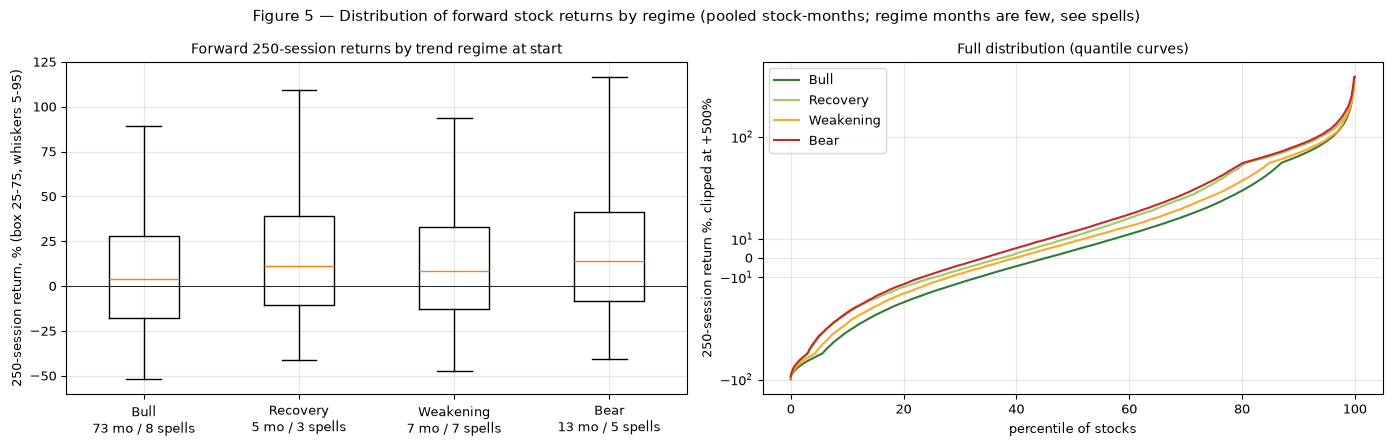

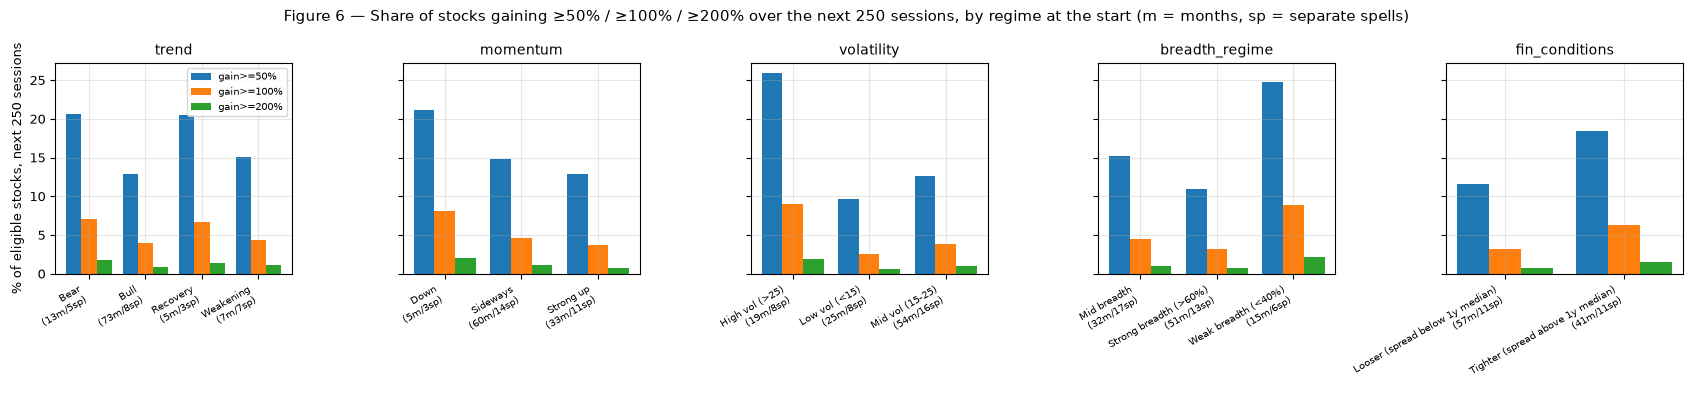

In [12]:
order = ["Bull", "Recovery", "Weakening", "Bear"]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
d = fp.dropna(subset=["r250", "trend"])
data = [d.loc[d["trend"] == k, "r250"].clip(-1, 3).values * 100 for k in order]
ax[0].boxplot(data, tick_labels=[f"{k}\n{BR['trend'].loc[k,'months']} mo / {BR['trend'].loc[k,'spells']} spells" for k in order], showfliers=False, whis=(5, 95))
ax[0].axhline(0, color="k", lw=.6); ax[0].set_ylabel("250-session return, % (box 25-75, whiskers 5-95)"); ax[0].set_title("Forward 250-session returns by trend regime at start")
for k in order:
    v = np.sort(d.loc[d["trend"] == k, "r250"].values); ax[1].plot(np.linspace(0, 100, len(v)), np.clip(v, -1, 5) * 100, label=k, color=TREND_COL[k])
ax[1].set_xlabel("percentile of stocks"); ax[1].set_ylabel("250-session return %, clipped at +500%"); ax[1].set_yscale("symlog", linthresh=50); ax[1].legend(); ax[1].set_title("Full distribution (quantile curves)")
fig.suptitle("Figure 5 — Distribution of forward stock returns by regime (pooled stock-months; regime months are few, see spells)"); fig.tight_layout(); save(fig, "fig05_return_distribution_by_regime")

fig, axs = plt.subplots(1, 5, figsize=(17, 4), sharey=True)
for a, (dim, t) in zip(axs, BR.items()):
    x = np.arange(len(t)); w = .27
    for j, c in enumerate(["gain>=50%", "gain>=100%", "gain>=200%"]):
        a.bar(x + (j - 1) * w, t[c] * 100, w, label=c)
    a.set_xticks(x); a.set_xticklabels([f"{i}\n({t.loc[i,'months']}m/{t.loc[i,'spells']}sp)" for i in t.index], fontsize=7, rotation=30, ha="right"); a.set_title(dim)
axs[0].set_ylabel("% of eligible stocks, next 250 sessions"); axs[0].legend(fontsize=7)
fig.suptitle("Figure 6 — Share of stocks gaining ≥50% / ≥100% / ≥200% over the next 250 sessions, by regime at the start (m = months, sp = separate spells)"); fig.tight_layout(); save(fig, "fig06_winner_share_by_regime")

### What §4 shows

* **[A] The typical one-year experience of an eligible stock is harsh, even among survivors.**
  * Median 250-session return: about +7.7%.
  * Median *worst drawdown* within that year: **−31%**; 18.5% of stock-years see a drawdown worse than −50%.
  * Gains of ≥ +100% are *reached* at some point within the year in 7.8% of cases but *held* to the year-end in only 4.5%. Big winners are volatile on the way up.
* **[A] Right-skew grows with horizon:** skewness 1.4 at 20 sessions vs 3.2 at 250. Gains ≥ +200% occur in about 1.1% of stock-years.
* **[A] Sector explains only about 8% of cross-sectional return variance** (today's sector labels). Most of what separates one stock's year from another's is stock-specific.
* **[A] By regime (all years):** starts in Bear, weak-breadth, high-VIX or tighter-credit months were followed by higher median returns, more ≥ +100% winners (Bear 7.0% vs Bull 3.9%; high VIX 9.0% vs low 2.6%) and *fewer* large losses.
* **[A] The robustness check changes the reading.** Excluding the 12 start months of 2020:
  * The ≥ +100% share is the same after Bear and Bull months (3.1% vs 3.0%), and **lower** after high-VIX months (1.8%) than mid-VIX months (3.5%).
  * What survives is a gap in *median* return: Bear 9.6% vs Bull 1.4%; weak breadth 10.6% vs strong breadth 0.05%. Lower loss rates after weak markets also survive.
  * By start year, the ≥ +100% share was 1.1–2.5% in 2017–2019 and 2021–2022, 3.4–4.4% in 2023–24, 7.8% in 2025 and **15.4% for 2020 starts**.
* **[B/C] Interpretation.** Exceptional winners are mostly a property of *market episodes*: the rebound after a crash lifts high-beta, beaten-down stocks together. Outside 2020 there is no stable "bad market → more 10-baggers" regularity in this data. There *is* a weaker, more general tendency for the typical stock to do better after broad weakness, consistent with market-level mean reversion. But it rests on 4–5 episodes, and survivorship (missing failures) inflates exactly those starts.

## 5. Breakout and breakdown dynamics

These are daily events in eligible stocks:
* **Breakout:** the first close above the prior N-session high, for N = 20, 55 and 252 (a 52-week high).
* **Breakdown:** the mirror image, using lows.

Outcomes:
* **Failed:** the stock closes back through the level within 10 sessions.
* **Sustained** (breakouts): 60 sessions later it is still above the level *and* has beaten the equal-weight universe.
* **Continued** (breakdowns): 60 sessions later it is still below the level and has lagged the universe.
* **Recovered:** 60 sessions later it is back on the other side of the level.

Excess returns are measured against the equal-weight median of the universe. Events cluster heavily in time, so the counts below are not independent observations.

In [13]:
EV = {(n, k): A.breakout_events(p, n, k) for n in (20, 55, 252) for k in ("up", "down")}
dens = pd.DataFrame({f"{'52w' if n == 252 else str(n) + 'd'} {'breakouts' if k == 'up' else 'breakdowns'}": A.density(p, e) for (n, k), e in EV.items()})
elig_days = p.eligible.sum(axis=1)
rows = []
for (n, k), e in EV.items():
    e = e.join(reg[["trend", "volatility", "breadth_regime"]], on="date")
    for g, sub in e.groupby("trend"):
        days = reg.index[reg["trend"] == g]
        rows.append({"event": f"{'52w' if n == 252 else str(n) + 'd'} {'breakout' if k == 'up' else 'breakdown'}", "trend": g, "events": len(sub), "per 100 eligible/day": 100 * len(sub) / elig_days.reindex(days).sum(),
                     "unique companies": sub["symbol"].nunique(), "failed in 10d": sub["failed10"].mean(), ("sustained 60d" if k == "up" else "continued 60d"): sub["sustained60"].mean(),
                     "recovered 60d": sub["recovered60"].mean(), "mean excess 60d": sub["x60"].mean(), "median excess 60d": sub["x60"].median(), "n with 60d": int(sub["x60"].notna().sum())})
BT = pd.DataFrame(rows)
print(BT.to_string(index=False))

        event     trend  events  per 100 eligible/day  unique companies  failed in 10d  sustained 60d  recovered 60d  mean excess 60d  median excess 60d  n with 60d  continued 60d
 20d breakout      Bear   22814                 4.175              2333         0.6464         0.4343         0.3858         0.005807           -0.01015       22781            NaN
 20d breakout      Bull  165145                 4.817              2807         0.6672          0.455         0.4268            0.013          0.0005245      152483            NaN
 20d breakout  Recovery    8461                 5.908              2097         0.7315         0.4355         0.4934         0.006509          -0.001737        8453            NaN
 20d breakout Weakening    5030                 1.887              1851         0.6672          0.378         0.4923         0.006146           -0.01059        5013            NaN
20d breakdown      Bear   21337                 3.905              2212         0.7006            Na

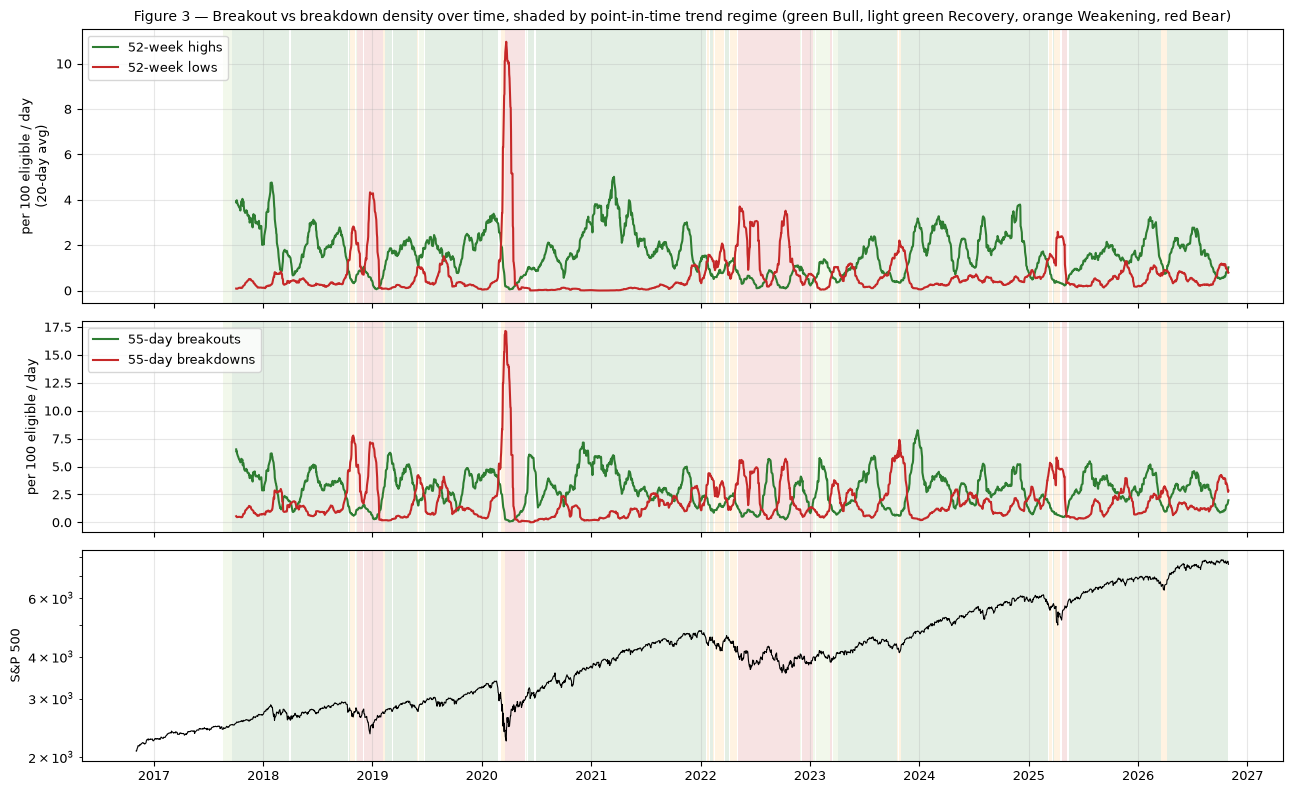

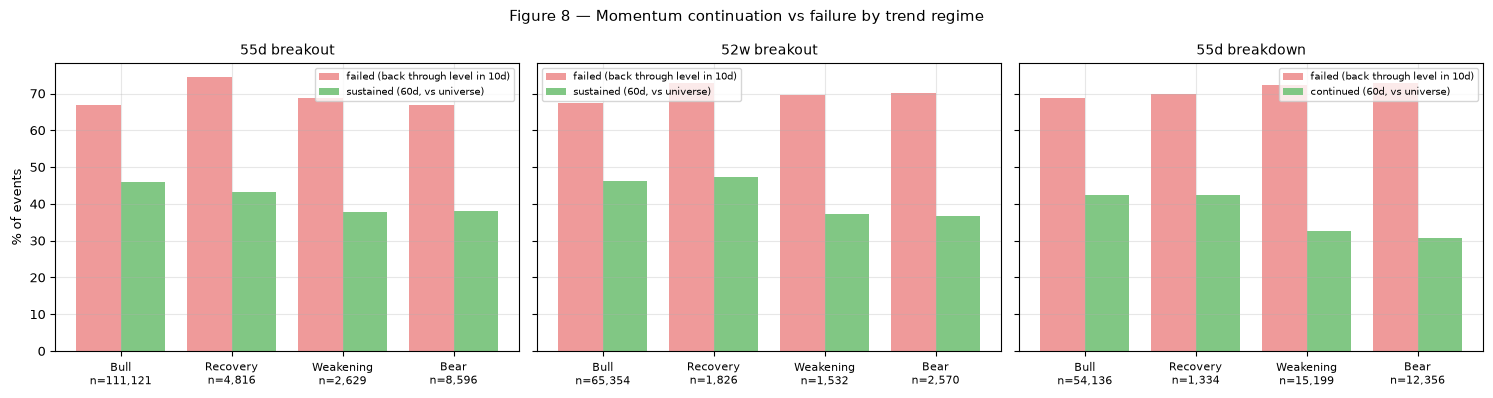

In [14]:
fig, ax = plt.subplots(3, 1, figsize=(13, 8), sharex=True, gridspec_kw={"height_ratios": [1.3, 1, 1]})
sm = dens.rolling(20, min_periods=10).mean()
ax[0].plot(sm.index, sm["52w breakouts"], color="#2e7d32", label="52-week highs"); ax[0].plot(sm.index, sm["52w breakdowns"], color="#c62828", label="52-week lows")
ax[1].plot(sm.index, sm["55d breakouts"], color="#2e7d32", label="55-day breakouts"); ax[1].plot(sm.index, sm["55d breakdowns"], color="#c62828", label="55-day breakdowns")
ax[2].plot(reg["spx"].dropna().index, reg["spx"].dropna(), "k", lw=.8); ax[2].set_yscale("log")
for a in ax:
    for k, col in TREND_COL.items():
        m = (reg["trend"] == k).astype(int); a.fill_between(reg.index, 0, 1, where=m.values == 1, transform=a.get_xaxis_transform(), color=col, alpha=.13, lw=0)
ax[0].set_ylabel("per 100 eligible / day\n(20-day avg)"); ax[1].set_ylabel("per 100 eligible / day"); ax[2].set_ylabel("S&P 500"); ax[0].legend(); ax[1].legend()
ax[0].set_title("Figure 3 — Breakout vs breakdown density over time, shaded by point-in-time trend regime (green Bull, light green Recovery, orange Weakening, red Bear)")
fig.tight_layout(); save(fig, "fig03_breakout_breakdown_density")

fig, axs = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for a, nm in zip(axs, ["55d breakout", "52w breakout", "55d breakdown"]):
    t = BT[BT["event"] == nm].set_index("trend").reindex(order)
    good = "sustained 60d" if "breakout" in nm else "continued 60d"
    x = np.arange(len(order)); a.bar(x - .2, t["failed in 10d"] * 100, .4, label="failed (back through level in 10d)", color="#ef9a9a"); a.bar(x + .2, t[good] * 100, .4, label=good.replace("60d", "(60d, vs universe)"), color="#81c784")
    a.set_xticks(x); a.set_xticklabels([f"{o}\nn={int(t.loc[o,'events']):,}" for o in order], fontsize=8); a.set_title(nm); a.legend(fontsize=7)
axs[0].set_ylabel("% of events")
fig.suptitle("Figure 8 — Momentum continuation vs failure by trend regime"); fig.tight_layout(); save(fig, "fig08_continuation_vs_failure")

In [15]:
e55 = EV[(55, "up")]
elig_sector = pd.Series(np.repeat(p.eligible.columns, p.eligible.sum(axis=0).values)).map(sec).fillna("Unknown").value_counts(normalize=True)
ev_sector = e55["symbol"].map(sec).fillna("Unknown").value_counts(normalize=True)
dn_sector = EV[(55, "down")]["symbol"].map(sec).fillna("Unknown").value_counts(normalize=True)
print("Sector share of 55-day breakouts / breakdowns vs share of eligible stock-days (today's sector labels):")
print(pd.DataFrame({"eligible stock-days": elig_sector, "55d breakouts": ev_sector, "55d breakdowns": dn_sector, "breakout lift": ev_sector / elig_sector}).sort_values("breakout lift").to_string())

Sector share of 55-day breakouts / breakdowns vs share of eligible stock-days (today's sector labels):
                        eligible stock-days  55d breakouts  55d breakdowns  breakout lift
symbol                                                                                   
Communication Services              0.04089        0.03683         0.04571         0.9007
Healthcare                           0.1378         0.1262          0.1465         0.9163
Consumer Defensive                  0.04763        0.04441         0.05101         0.9324
Consumer Cyclical                    0.1232         0.1166          0.1346         0.9466
Basic Materials                     0.04065        0.03921         0.04408         0.9646
Real Estate                         0.06888        0.06979         0.07052          1.013
Unknown                             0.01535        0.01578         0.01536          1.028
Utilities                           0.03092         0.0319         0.02675          1.0

### What §5 shows

* **[A] Most breakouts fail quickly in every regime.** 65–75% of 20-day, 55-day and 52-week breakouts close back below the breakout level within 10 sessions, about the same in Bull, Bear, Recovery and Weakening markets.
* **[A] What follows depends on the market regime:**
  * In **Bull** markets, 55-day and 52-week breakouts beat the universe by +1.5–1.6% on average over 60 sessions (median +0.3%).
  * In **Bear** markets they *lag* (52-week highs: mean −1.7%, median −3.8%).
  * 55-day and 52-week breakdowns in **Bear and Weakening** markets mostly *recover*: 61–69% are back above the level 60 sessions later, with positive average excess returns of +1.9% to +3.7%. Twenty-day breakdowns recover less (57–64%). Breakdowns in Bull markets show a much weaker reversal (46–50% recovered, mean excess −0.6% to +0.9%).
* **[A] Breakout density tracks the market's recent past.** 52-week highs and lows swing violently with the market (Figure 3).
* **[A] By sector**, breakouts are spread almost in proportion to the universe (lift 0.90–1.06). No sector is a breakout factory.

## 6. Exceptional winners: what did they look like *before* the move?

A **winner** is an eligible stock-month whose close 250 sessions later is at least 50%, 100% or 200% higher. Each characteristic is measured at the start month with data available then, and is **ranked within that month** (percentiles). That removes date effects: we compare stocks with other stocks on the same date, not 2020 with 2022.

Each table compares the winner rate in each decile with the **base rate of the whole eligible universe**, not with other winners. Losses (≤ −50%) are shown next to gains because a characteristic that raises both is a volatility exposure, not a selection skill.

Market capitalisation is **not available point-in-time**; 20-day dollar volume is used as a size proxy. Fundamentals are excluded, because SEC point-in-time coverage is 20 companies.

In [16]:
d = fp.dropna(subset=["r250"]).copy()
for x in (0.5, 1.0, 2.0): d[f"W{int(x*100)}"] = d["r250"] >= x
d["L50"] = d["r250"] <= -0.5
base = {c: d.groupby("date")[c].mean().mean() for c in ("W50", "W100", "W200", "L50")}
print("Base rates (month-equal):", {k: f"{v:.2%}" for k, v in base.items()})
w = d[d["W200"]].sort_values("date")
epi, lastd = [], {}
for s, t in zip(w["symbol"], w["date"]):
    if s not in lastd or (t - lastd[s]).days > 365: epi.append((s, t))
    lastd[s] = t
print(f"W200 stock-months: {len(w):,}; unique companies: {w['symbol'].nunique()}; independent episodes (a new episode needs a 12-month gap): {len(epi)}")
print("W200 stock-months by start year:", w["date"].dt.year.value_counts().sort_index().to_dict())
FEATS = {"ret126_pct": "6-month return (relative strength)", "vol60_pct": "60-day volatility", "adv20_musd_pct": "dollar volume (size proxy)", "volume_trend_pct": "volume trend 20d/120d",
         "dist_52w_high_pct": "distance from 52-week high (high = near the high)", "ret21_pct": "1-month return"}
rows = []
for f, label in FEATS.items():
    dd = d.dropna(subset=[f]); dd["dec"] = np.minimum((dd[f] * 10).astype(int), 9) + 1
    g = dd.groupby("dec")
    for dec, sub in g:
        rows.append({"feature": label, "decile": dec, "stock-months": len(sub), **{f"{c} rate": sub.groupby("date")[c].mean().mean() for c in ("W50", "W100", "W200", "L50")}})
FT = pd.DataFrame(rows)
for c in ("W100", "W200", "L50"): FT[f"{c} lift"] = FT[f"{c} rate"] / base[c]
print(FT[FT["decile"].isin([1, 2, 5, 9, 10])].to_string(index=False))
for flag, lab in (("new55_high_last20", "made a new 55-day high in the last 20 sessions"),):
    for v, sub in d.groupby(d[flag] > 0):
        print(f"{lab} = {v}: n {len(sub):,}; W100 {sub.groupby('date')['W100'].mean().mean():.2%}; W200 {sub.groupby('date')['W200'].mean().mean():.2%}; L50 {sub.groupby('date')['L50'].mean().mean():.2%}")
d["price_bucket"] = pd.cut(d["price"], [5, 10, 20, 50, 1e9], labels=["$5-10", "$10-20", "$20-50", ">$50"], right=False)
print(d.groupby("price_bucket").apply(lambda s: pd.Series({"n": len(s), "W100": s.groupby("date")["W100"].mean().mean(), "L50": s.groupby("date")["L50"].mean().mean()})).to_string())

Base rates (month-equal): {'W50': '14.47%', 'W100': '4.51%', 'W200': '1.05%', 'L50': '4.93%'}
W200 stock-months: 1,931; unique companies: 464; independent episodes (a new episode needs a 12-month gap): 522
W200 stock-months by start year: {2017: 12, 2018: 24, 2019: 141, 2020: 671, 2021: 50, 2022: 77, 2023: 215, 2024: 210, 2025: 531}


                                          feature  decile  stock-months  W50 rate  W100 rate  W200 rate  L50 rate  W100 lift  W200 lift  L50 lift
               6-month return (relative strength)       1         17933    0.2058    0.09197     0.0251    0.1321      2.037      2.379     2.677
               6-month return (relative strength)       2         18061    0.1567    0.04935    0.01246   0.06009      1.093      1.181     1.218
               6-month return (relative strength)       5         18078    0.1193    0.02671   0.004981    0.0288     0.5916     0.4722    0.5837
               6-month return (relative strength)       9         18095    0.1431    0.04068   0.008558   0.03556     0.9012     0.8113    0.7208
               6-month return (relative strength)      10         18121    0.2109     0.0901    0.02615   0.08087      1.996      2.479     1.639
                                60-day volatility       1         17990   0.04073   0.002582  0.0003503  0.009399     0.0572

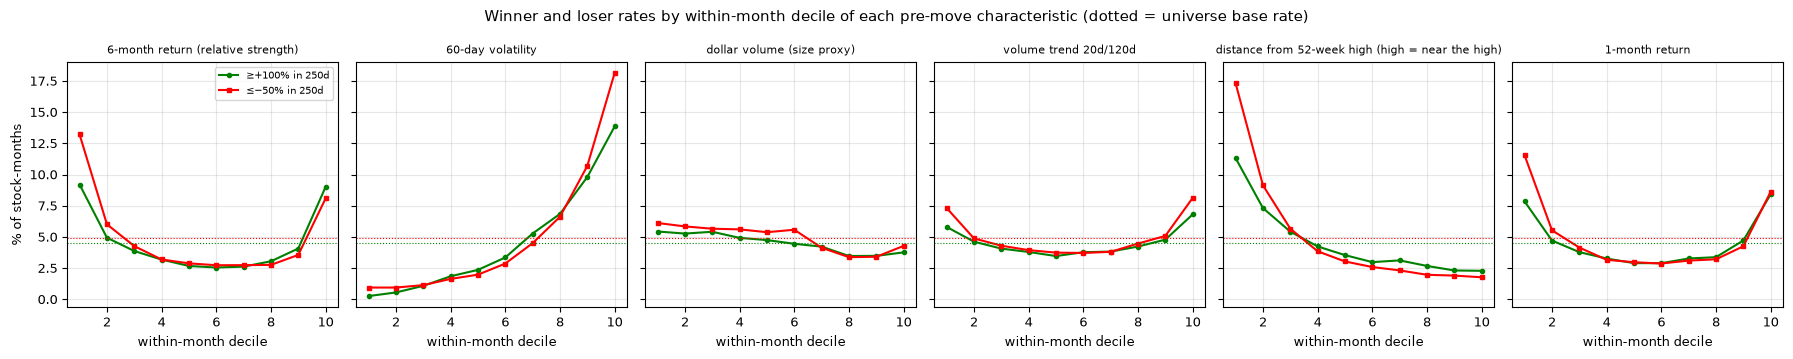

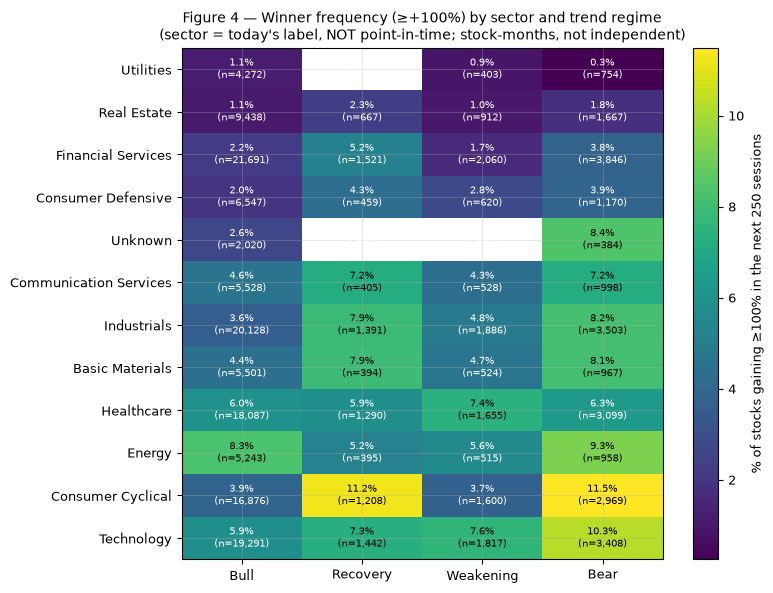

In [17]:
fig, axs = plt.subplots(1, len(FEATS), figsize=(18, 3.6), sharey=True)
for a, (f, label) in zip(axs, FEATS.items()):
    t = FT[FT["feature"] == label]
    a.plot(t["decile"], t["W100 rate"] * 100, "g-o", ms=3, label="≥+100% in 250d"); a.plot(t["decile"], t["L50 rate"] * 100, "r-s", ms=3, label="≤−50% in 250d")
    a.axhline(base["W100"] * 100, color="g", ls=":", lw=.8); a.axhline(base["L50"] * 100, color="r", ls=":", lw=.8); a.set_title(label, fontsize=8); a.set_xlabel("within-month decile")
axs[0].set_ylabel("% of stock-months"); axs[0].legend(fontsize=7)
fig.suptitle("Winner and loser rates by within-month decile of each pre-move characteristic (dotted = universe base rate)"); fig.tight_layout(); save(fig, "fig06b_winner_characteristics")

hm = d.dropna(subset=["trend"]).groupby(["sector", "trend"]).apply(lambda s: pd.Series({"rate": s.groupby("date")["W100"].mean().mean(), "n": len(s)})).reset_index()
R = hm.pivot(index="sector", columns="trend", values="rate").reindex(columns=order); N = hm.pivot(index="sector", columns="trend", values="n").reindex(columns=order)
R = R.where(N >= 300); R = R.loc[R.mean(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(8, 6)); im = ax.imshow(R.values * 100, cmap="viridis", aspect="auto")
ax.set_xticks(range(len(order))); ax.set_xticklabels(order); ax.set_yticks(range(len(R))); ax.set_yticklabels(R.index)
for i in range(R.shape[0]):
    for j in range(R.shape[1]):
        v, n = R.values[i, j], N.loc[R.index[i], order[j]]
        ax.text(j, i, "n<300" if np.isnan(v) else f"{v*100:.1f}%\n(n={int(n):,})", ha="center", va="center", fontsize=7, color="w" if (np.isnan(v) or v * 100 < np.nanmax(R.values * 100) * .6) else "k")
plt.colorbar(im, label="% of stocks gaining ≥100% in the next 250 sessions")
ax.set_title("Figure 4 — Winner frequency (≥+100%) by sector and trend regime\n(sector = today's label, NOT point-in-time; stock-months, not independent)"); fig.tight_layout(); save(fig, "fig04_winner_heatmap_sector_regime")

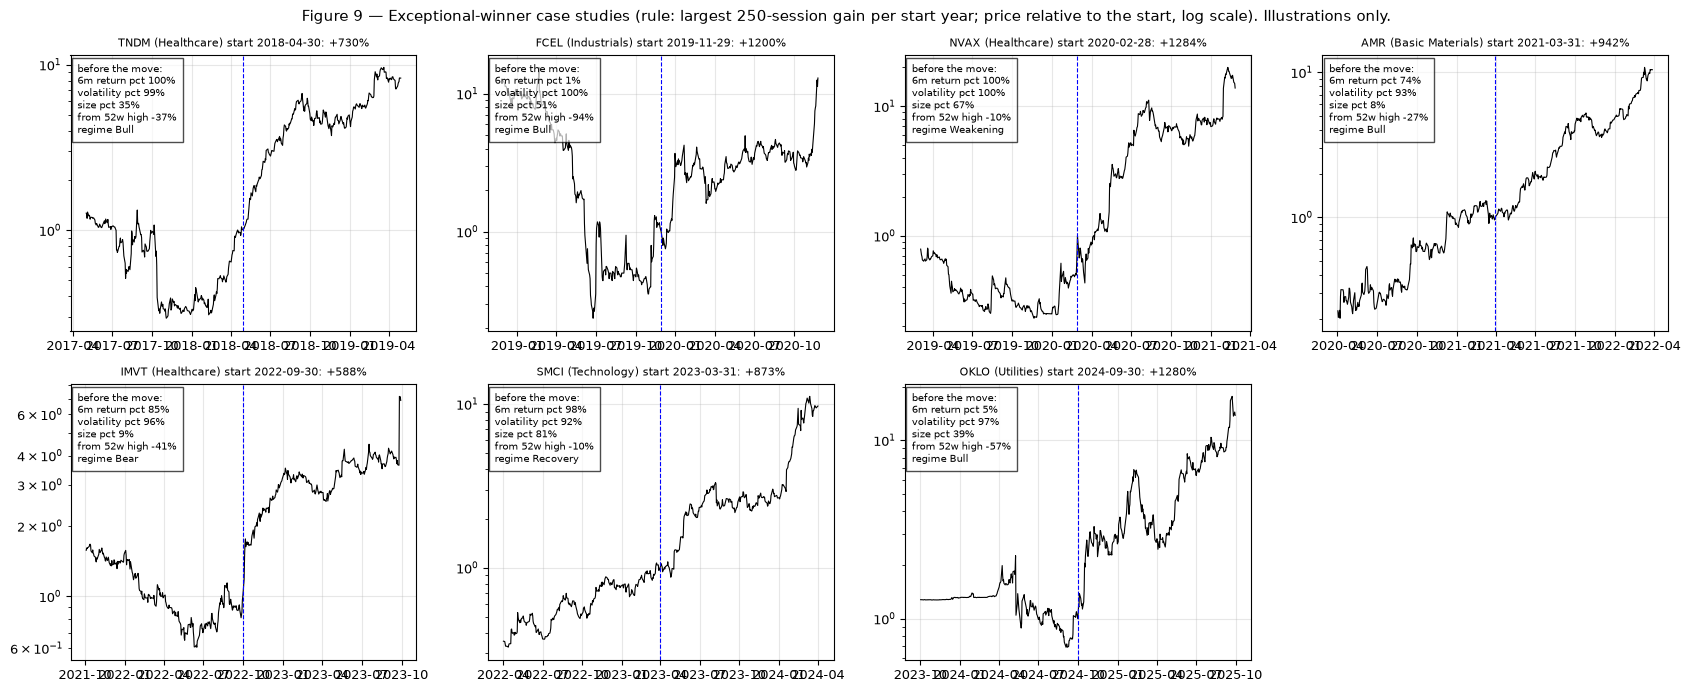

symbol       date  r250  maxdd250  ret126_pct  vol60_pct  adv20_musd_pct  dist_52w_high     trend          sector
  TNDM 2018-04-30 7.301    -0.444       0.998     0.9888          0.3542        -0.3746      Bull      Healthcare
  FCEL 2019-11-29    12   -0.6215     0.01166          1          0.5061        -0.9397      Bull     Industrials
  NVAX 2020-02-28 12.84   -0.5681      0.9958     0.9988          0.6741       -0.09656 Weakening      Healthcare
   AMR 2021-03-31 9.424   -0.3222      0.7437     0.9313         0.07664        -0.2737      Bull Basic Materials
  IMVT 2022-09-30  5.88   -0.2799      0.8536     0.9588         0.09278        -0.4148      Bear      Healthcare
  SMCI 2023-03-31 8.734   -0.3446      0.9796     0.9217          0.8079       -0.09978  Recovery      Technology
  OKLO 2024-09-30  12.8   -0.6432     0.05016     0.9675          0.3909        -0.5697      Bull       Utilities


In [18]:
# Case studies: a FIXED rule chosen before looking: for each start year 2018-2024, the single largest 250-session gain among eligible stock-months (one per company).
cases, used = [], set()
for y in range(2018, 2025):
    sub = d[(d["date"].dt.year == y) & ~d["symbol"].isin(used)].sort_values("r250", ascending=False)
    if len(sub): r = sub.iloc[0]; cases.append(r); used.add(r["symbol"])
fig, axs = plt.subplots(2, 4, figsize=(17, 7)); axs = axs.ravel()
for a, r in zip(axs, cases):
    s = C[r["symbol"]].dropna(); i = s.index.get_loc(r["date"]); w = s.iloc[max(0, i - 250): i + 251]
    a.plot(w.index, w / s.iloc[i], "k-", lw=.8); a.axvline(r["date"], color="b", ls="--", lw=.8); a.set_yscale("log")
    a.set_title(f"{r['symbol']} ({r.get('sector','?')}) start {r['date'].date()}: {r['r250']:+.0%}", fontsize=8)
    a.text(.02, .97, f"before the move:\n6m return pct {r['ret126_pct']:.0%}\nvolatility pct {r['vol60_pct']:.0%}\nsize pct {r['adv20_musd_pct']:.0%}\nfrom 52w high {r['dist_52w_high']:+.0%}\nregime {r['trend']}", transform=a.transAxes, va="top", fontsize=7, bbox=dict(fc="w", alpha=.7))
axs[-1].axis("off")
fig.suptitle("Figure 9 — Exceptional-winner case studies (rule: largest 250-session gain per start year; price relative to the start, log scale). Illustrations only."); fig.tight_layout(); save(fig, "fig09_winner_case_studies")
print(pd.DataFrame(cases)[["symbol", "date", "r250", "maxdd250", "ret126_pct", "vol60_pct", "adv20_musd_pct", "dist_52w_high", "trend", "sector"]].to_string(index=False))

### What §6 shows

* **[A] Base rates (eligible stock-months, 250 sessions):** ≥ +50% 14.5%, ≥ +100% 4.5%, ≥ +200% 1.05%, ≤ −50% 4.9%. The 1,931 stock-months with ≥ +200% come from 464 companies in about 522 independent episodes, and 35% of them start in 2020.
* **[B] Volatility is the dominant pre-move characteristic, for both tails.**
  * In the top within-month volatility decile, a ≥ +200% gain is 4.8× as likely as the base rate, and a ≤ −50% loss 3.7× as likely.
  * In the two lowest deciles, ≥ +100% gains are almost absent (0.26% and 0.54%).

  **A right-tail outcome is, first of all, a volatility exposure.**
* **[A] Every momentum-style feature shows a U-shape that raises both tails.** The worst and best 6-month performers, and the worst and best 1-month performers, have about 2× the base rate of ≥ +100% winners *and* 1.6–2.7× the rate of ≤ −50% losers.
* **[A] Near the 52-week high is the *least* likely place for a one-year doubling.**
  * Stocks far below their high (bottom decile) have 2.5× the base ≥ +100% rate and 3.5× the ≤ −50% rate.
  * Stocks at the top decile (near the high) have half the base winner rate *and* about a third of the loser rate.

  Being near the high lowers variance; it does not select winners.
* **[A] A new 55-day high in the last 20 sessions does not raise the ≥ +100% rate** (4.26% vs 4.52%), but it lowers the ≤ −50% rate (3.95% vs 5.55%). This matches PR #90: breakouts did not select the right tail.
* **[A] Lower share prices show higher winner rates** ($5–10: 10.0% ≥ +100%, vs >$50: 2.4%) and higher loser rates. This is the same volatility story.
* **[A] Sector × regime (Figure 4):** the highest ≥ +100% rates are in Consumer Cyclical and Technology starting in Bear or Recovery months (10–12%); the lowest are in Utilities and Real Estate (~1%). The cells are dominated by 2020 and use today's sector labels.
* **Case studies (fixed rule, one per start year):** TNDM, FCEL, NVAX, AMR, IMVT, SMCI and OKLO all sat in the top volatility decile (92nd–100th percentile) *before* the move. Five of the seven had extreme 6-month returns (above the 95th or below the 5th percentile). Four were 37–94% below their 52-week high. All suffered drawdowns of −28% to −64% *inside* the winning year.

## 7. Relationships: what moves with what, and what comes before what

Each row is a Spearman rank correlation between two **monthly** series, with a moving-block bootstrap 95% interval. The block length covers the forward window, so overlapping windows are not treated as independent. **n_eff** is a rough count of non-overlapping observations, and it is small for 250-session windows.

**Contemporaneous** rows say what moves together. **Forward** rows say what came before what, which is still not causation, and with an n_eff this small it is rarely more than a hint.

In [19]:
MM = pd.DataFrame(index=me)
MM["breadth"] = reg["breadth"].reindex(me); MM["vix"] = reg["vix"].reindex(me); MM["baa"] = reg["baa10y"].reindex(me)
MM["w100_next250"] = fp.dropna(subset=["r250"]).groupby("date")["r250"].apply(lambda s: (s >= 1).mean())
MM["w50_next250"] = fp.dropna(subset=["r250"]).groupby("date")["r250"].apply(lambda s: (s >= .5).mean())
MM["b55_density"] = dens["55d breakouts"].rolling(20, min_periods=10).mean().reindex(me)
MM["hi52_minus_lo52"] = (dens["52w breakouts"] - dens["52w breakdowns"]).rolling(20, min_periods=10).mean().reindex(me)
spxd = spx.reindex(C.index).ffill()
for h in (20, 60): MM[f"spx_next{h}"] = (spxd.shift(-h) / spxd - 1).reindex(me)
MM["spx_past20"] = (spxd / spxd.shift(20) - 1).reindex(me)
nas = A.fred("NASDAQCOM").reindex(C.index).ffill(); d10 = A.fred("DGS10").reindex(C.index).ffill()
mret = lambda s: (s.reindex(me) / s.reindex(me).shift(1) - 1)
MM["nasdaq_minus_spx_month"] = mret(nas) - mret(spxd); MM["d10y_month"] = d10.reindex(me) - d10.reindex(me).shift(1)
MM["nasdaq_minus_spx_next_month"] = MM["nasdaq_minus_spx_month"].shift(-1)
MM["dispersion_next60"] = fp.dropna(subset=["r60"]).groupby("date")["r60"].apply(lambda s: s.quantile(.75) - s.quantile(.25))
past60 = (C / C.shift(60) - 1).where(p.eligible)
MM["dispersion_past60"] = past60.reindex(me).apply(lambda r: r.quantile(.75) - r.quantile(.25), axis=1)
def mom_spread(x):
    x = x.dropna(subset=["ret126", "r60"]);
    if len(x) < 200: return np.nan
    q = x["ret126"].rank(pct=True); return x.loc[q > .9, "r60"].mean() - x.loc[q <= .1, "r60"].mean()
MM["momentum_spread_next60"] = fp.groupby("date").apply(mom_spread)
REL = [("Market breadth → share of stocks gaining ≥100% over next 250d", "breadth", "w100_next250", 12, "forward"),
       ("Market breadth → share gaining ≥50% over next 250d", "breadth", "w50_next250", 12, "forward"),
       ("VIX → share gaining ≥100% over next 250d", "vix", "w100_next250", 12, "forward"),
       ("55d breakout density → S&P 500 next 20d", "b55_density", "spx_next20", 1, "forward"),
       ("55d breakout density → S&P 500 next 60d", "b55_density", "spx_next60", 3, "forward"),
       ("55d breakout density ~ S&P 500 past 20d", "b55_density", "spx_past20", 1, "contemporaneous"),
       ("Net new 52w highs → S&P 500 next 60d", "hi52_minus_lo52", "spx_next60", 3, "forward"),
       ("10y yield change ~ NASDAQ minus S&P 500, same month", "d10y_month", "nasdaq_minus_spx_month", 1, "contemporaneous"),
       ("10y yield change → NASDAQ minus S&P 500, next month", "d10y_month", "nasdaq_minus_spx_next_month", 1, "forward"),
       ("Credit spread (Baa−10y) → dispersion of next-60d returns", "baa", "dispersion_next60", 3, "forward"),
       ("Credit spread ~ dispersion of past-60d returns", "baa", "dispersion_past60", 3, "contemporaneous"),
       ("VIX → momentum spread (top − bottom decile of 6m return), next 60d", "vix", "momentum_spread_next60", 3, "forward"),
       ("Market breadth → momentum spread next 60d", "breadth", "momentum_spread_next60", 3, "forward")]
RT = pd.DataFrame([{"relationship": nm, "type": typ, **A.spearman_block(MM[x], MM[y], b)} for nm, x, y, b, typ in REL])
RT["interval excludes 0"] = (RT["lo"] > 0) | (RT["hi"] < 0)
print(RT.to_string(index=False))
print("\nMomentum spread (next 60d, top minus bottom decile of 6-month return) by volatility regime at the start:")
MM["volreg"] = reg["volatility"].reindex(me)
print(MM.groupby("volreg")["momentum_spread_next60"].agg(["count", "mean", "median"]).to_string())

                                                      relationship            type    rho     lo     hi  n_months  n_eff  interval excludes 0
     Market breadth → share of stocks gaining ≥100% over next 250d         forward -0.217  -0.51  0.097        98    8.2                False
                Market breadth → share gaining ≥50% over next 250d         forward -0.317 -0.568 -0.046        98    8.2                 True
                          VIX → share gaining ≥100% over next 250d         forward  0.242 -0.167   0.57        98    8.2                False
                           55d breakout density → S&P 500 next 20d         forward -0.155 -0.337  0.055       108    108                False
                           55d breakout density → S&P 500 next 60d         forward -0.147 -0.403  0.088       106   35.3                False
                           55d breakout density ~ S&P 500 past 20d contemporaneous  0.417  0.241  0.582       109    109                 True
      

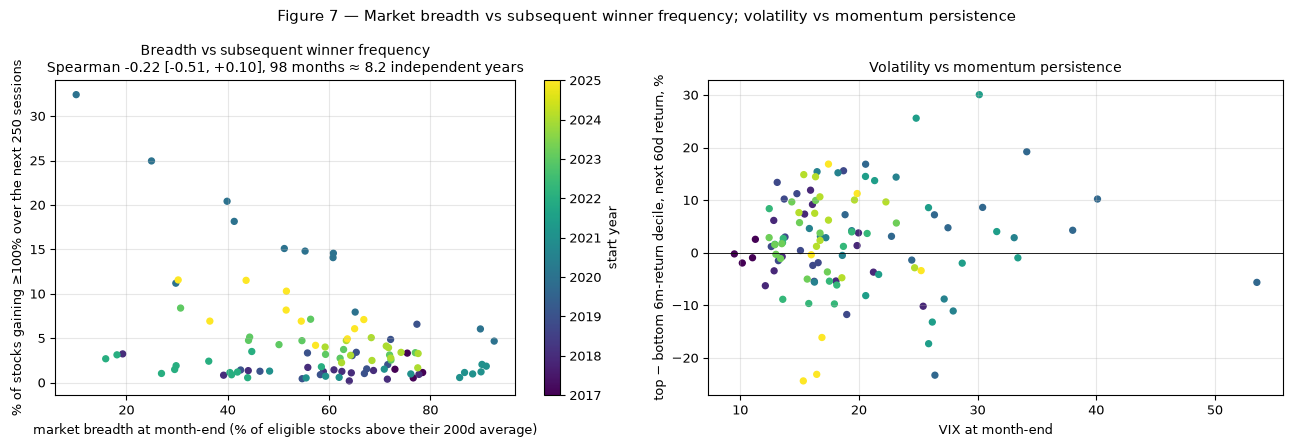

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
x = MM.dropna(subset=["breadth", "w100_next250"])
sc = ax[0].scatter(x["breadth"] * 100, x["w100_next250"] * 100, c=x.index.year, cmap="viridis", s=18)
plt.colorbar(sc, ax=ax[0], label="start year"); ax[0].set_xlabel("market breadth at month-end (% of eligible stocks above their 200d average)"); ax[0].set_ylabel("% of stocks gaining ≥100% over the next 250 sessions")
r = RT.iloc[0]; ax[0].set_title(f"Breadth vs subsequent winner frequency\nSpearman {r['rho']:+.2f} [{r['lo']:+.2f}, {r['hi']:+.2f}], {r['n_months']} months ≈ {r['n_eff']} independent years")
x2 = MM.dropna(subset=["vix", "momentum_spread_next60"]); ax[1].scatter(x2["vix"], x2["momentum_spread_next60"] * 100, s=18, c=x2.index.year, cmap="viridis"); ax[1].axhline(0, color="k", lw=.6)
ax[1].set_xlabel("VIX at month-end"); ax[1].set_ylabel("top − bottom 6m-return decile, next 60d return, %"); ax[1].set_title("Volatility vs momentum persistence")
fig.suptitle("Figure 7 — Market breadth vs subsequent winner frequency; volatility vs momentum persistence"); fig.tight_layout(); save(fig, "fig07_breadth_vs_winners")

### What §7 shows

* **[A] Breakout density is contemporaneous, not predictive.** It correlates with the past 20 sessions' S&P 500 return (+0.42, interval +0.24 to +0.58) but *not* with the next 20 or 60 sessions (−0.15 and −0.15, intervals include 0).
* **[A, weak] Lower breadth → more ≥ +50% winners the next year:** ρ = −0.32 (−0.57 to −0.05). But n_eff is only about 8 independent years, and the ≥ +100% version (−0.22) includes 0. Given the 2020 dominance in §4, this is not a regularity we can rely on.
* **[A] No detectable relationships:**
  * 10-year yield changes vs NASDAQ-minus-S&P 500 performance (same month −0.14; next month −0.08; both include 0).
  * Credit spreads vs future dispersion of returns.
  * VIX or breadth vs momentum persistence.
* **[C]** Momentum's 60-session spread (top minus bottom decile of 6-month return) averaged about 0 after high-VIX months, vs +2.4% to +2.8% after low- and mid-VIX months. That is consistent with the "momentum crash" literature, but the correlation interval includes 0 and there are only 20 high-VIX months.

## 8. Conclusions

### The ten most important empirical findings

1. **[A] Today's stock list is not the historical universe.** 98.3% of 2017's eligible stocks are still priced in 2026. Loss tails are understated and winner rates overstated everywhere in this dataset.
2. **[B] The right tail is mostly a volatility exposure.** The top volatility decile has 4.8× the base rate of +200% years and 3.7× the rate of −50% years; low-volatility stocks almost never double.
3. **[A] Exceptional winners are clustered in market episodes.** The ≥ +100% share was 15.4% for 2020 starts, 7.8% for 2025, and 1–4% in other years. With 2020 excluded, the regime differences in winner frequency disappear or reverse.
4. **[A/C] Starts in Bear or weak-breadth months had higher *median* one-year returns even outside 2020** (Bear +9.6% vs Bull +1.4%), with fewer large losses. This rests on 4–5 episodes, and survivorship favours exactly these starts.
5. **[A] Being near the 52-week high halves the chance of doubling and cuts the chance of halving to about a third.** "Near highs" lowers variance; it does not select winners.
6. **[A] 65–75% of breakouts close back below the level within 10 sessions, in every regime.** Breakouts in Bull markets beat the universe slightly over 60 sessions; in Bear markets they lag.
7. **[A] 55-day and 52-week breakdowns in Bear and Weakening markets mostly recover:** 61–69% are back above the level after 60 sessions, with positive excess returns.
8. **[A] Breakout density and net new highs measure the past, not the future:** ρ +0.42 with the trailing month, about −0.15 (including 0) with the next one.
9. **[A] Macro event days:** FOMC days are 1.3× as volatile as normal (cuts 2.6×, with negative day-0 returns, a selection effect). Jobs-report days are 1.18× (1.42× when unemployment rose). CPI days are barely more volatile than normal over 2016–2026 (1.08×). No first-release split of CPI or jobs data shows a forward return difference.
10. **[A] A winner's path is brutal.** The median eligible stock suffers a −31% drawdown within a year. ≥ +100% is reached at some point in 7.8% of stock-years but held to the year-end in 4.5%.

### Surprising or counterintuitive

* **Near the 52-week high** was where one-year doublings were *least* likely, not most.
* **The apparent "bad market → more big winners" pattern is almost entirely 2020.** Without it, high-VIX starts produce *fewer* doublings.
* **Tighter credit** was followed by better returns, not worse.
* **CPI days** were hardly more volatile than normal days over the full decade.

### Strongest relationships (still descriptive)

* Volatility → both tails, about a 3–5× lift, monotonic and within-date.
* Distance from the 52-week high → both tails, U-shaped momentum features → both tails.
* Breakout density ~ past returns, contemporaneous.
* Start year (episode) → winner frequency.

### Weak or unsupported

* Breadth, VIX and credit as forecasters of winners or of momentum.
* Rate changes vs growth stocks.
* FOMC, CPI and jobs outcome splits as forward signals.
* Breakout density as a market forecaster.
* Sector as a breakout source.

### Major limitations

1. **Survivorship:** essentially no delisted companies.
2. **Only 2016-09 → 2026-10:** 4–5 bear episodes, one of them extreme (2020).
3. **Adjusted prices only.**
4. **No point-in-time market cap, sector or fundamentals.**
5. **No consensus macro expectations**, so §3 is descriptive and not a surprise study.
6. **This price history has been examined by earlier First Light studies.**
7. **High-yield spreads are available only for 3 years;** the Baa spread is used instead. NFCI is revised.
8. **Overlapping windows:** the intervals use block bootstraps, but the effective sample for one-year outcomes is about 8 independent years.

### Three hypotheses worth testing independently (class C)

1. **Volatility-matched selection.** Any candidate right-tail signal (fundamental acceleration, insider buying, a catalyst) must raise the ≥ +100% rate *within the same volatility decile* without raising the ≤ −50% rate as much. Otherwise it is only a volatility tilt.
2. **Post-drawdown typical return.** After the market has been in a Bear or weak-breadth state, the typical stock's one-year return is higher than after Bull or strong-breadth states, with fewer large losses. This needs either more history (pre-2016, other markets) or a pre-registered forward record.
3. **Breakdown reversal in weak markets.** 55-day and 52-week breakdowns that occur in Bear or Weakening regimes outperform volatility-matched peers over 60 sessions. This should be tested forward only, because this history has been looked at.

### Recommended next data improvements

1. **Delisted-company price history** (the single biggest fix).
2. **A longer price history,** at least back to 2000, to include 2000–02 and 2008–09.
3. **Point-in-time market cap** from SEC filings (`dei:EntityCommonStockSharesOutstanding`) and point-in-time sector going forward (`sector_observation` is already recording).
4. **Consensus macro forecasts,** if a licensable source exists, to turn §3 into a genuine surprise study.
5. **ALFRED vintages for NFCI,** and a licensed long high-yield-spread history.